In [1]:
# Import statement
import pandas as pd
import numpy as np
import glob
import seaborn as sns
import matplotlib.pyplot as plt
import pingouin as pg
import statsmodels.formula.api as smf

In [2]:
# Set a few useful variables
preprocdata_dir="preprocessed_data"
preprocdata_file="df_rlwm_clean.csv"

In [3]:
# Load the preprocessed data
df_rlwm=pd.read_csv(f'{preprocdata_dir}/{preprocdata_file}')
# Drop the Unnamed index created by earlier operations
df_rlwm.drop(columns="Unnamed: 0", inplace=True)
# Keep only the 'learning' phase 
df_rlwm=df_rlwm[df_rlwm['trial_mode']=='learning'].reset_index(drop=True)
# Exclude the first block, which is considered training (it had also twice as many repetitions per stim)
df_rlwm=df_rlwm[df_rlwm['blockId']>0].reset_index(drop=True)


In [4]:
# Inspect the columns
display(df_rlwm.columns)

Index(['trial_index', 'time_elapsed', 'rt', 'timeEndTrial', 'blockId', 'setId',
       'setSize', 'stimId', 'trial_mode', 'correct_feedback', 'key_response',
       'correct', 'time_startFadeIn', 'time_endFadeIn', 'feedback', 'imageid',
       'setid', 'subjid', 'STAI', 'PSS', 'BDI'],
      dtype='str')

In [5]:
# First of all, let's check if the key prediction of the RLWM task is validated
# However, we realize that we are missing a key component: the repetition count of each stimulus into each block
# This is a key lesson for you: always check before running your whole experiment that you log all the information you need
# to make your analyses!
# Here, fortunately, we are able to recompute this using blockId and stimId information
df_rlwm["stim_rep"] = (
    df_rlwm
    .groupby(["subjid", "blockId", "stimId"])
    .cumcount()
)

In [6]:
# Now we group by subjid, setSize and stim_rep to reproduce the plot of Collins et al.
df_rlwm_avg=df_rlwm.groupby(by=['subjid', 'setSize', 'stim_rep']).mean(numeric_only=True).reset_index()

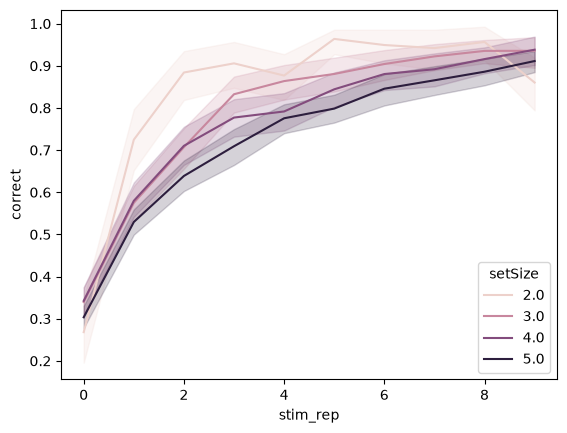

In [8]:
# We make a quick plot using Seaborn, which is essentially a "wrapper" around matplotlib (the core plotting library of Python)
# Seaborn is meant to work with Pandas dataframes, which makes our lives much easier
g=sns.lineplot(data=df_rlwm_avg, x='stim_rep', y='correct', hue='setSize')

<Axes: xlabel='stim_rep', ylabel='correct'>

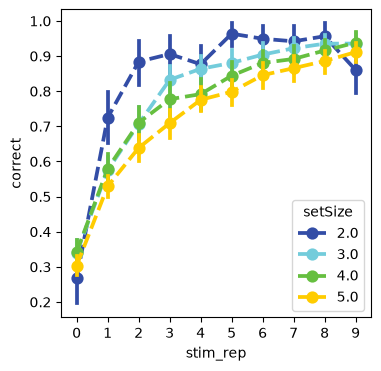

In [9]:
# We make again the same plot using the same color code as Collins et al by defining a custom "palette" (dictionary whose keys match the possible values of setSize)
# We also use a different type of Seaborn plot that gives us exactly the same as in the original article.
collins_palette={
  2.0: (0.2,0.30,0.65),
  3.0: (0.45,0.80,0.86),
  4.0: (0.4,0.75,0.25),
  5.0: (1.0,0.8,0.0)
}
fig,ax = plt.subplots(figsize=(4,4))
sns.pointplot(data=df_rlwm_avg, x='stim_rep', y='correct', hue='setSize', palette=collins_palette, linestyles='--')

In [10]:
# Now, let see if our result is significant using the statistical package pingouin, which is essentially a wrapper around another more complex library called statsmodels
# Pingouin is meant to work with Pandas dataframes, which again makes our lives much easier!

aov=pg.rm_anova(data=df_rlwm_avg, dv="correct", within=['setSize', 'stim_rep'], subject='subjid')
print(aov.round(3))

# What can you say about the results?
# Anything that bothers you?


               Source      SS  ddof1  ddof2      MS        F  p_unc  \
0             setSize   4.297      3    201   1.432   23.153    0.0   
1            stim_rep  90.318      9    603  10.035  406.926    0.0   
2  setSize * stim_rep   4.093     27   1809   0.152    8.176    0.0   

   p_GG_corr    ng2    eps  
0        0.0  0.047  0.884  
1        0.0  0.511  0.458  
2        0.0  0.045  0.316  


c:\Users\Romain\miniforge3\envs\neurograd\Lib\site-packages\pingouin\distribution.py:514: UserWarning: Epsilon values might be innaccurate in two-way repeated measures design where each  factor has more than 2 levels. Please  double-check your results.
  warnings.warn(


In [11]:
# We will re-run a similar analysis using a mixed-effect model treating setSize and stim_rep as continuous variables
model = smf.mixedlm(
    "correct ~ setSize * stim_rep",
    data=df_rlwm_avg,
    groups=df_rlwm_avg["subjid"]
)

res = model.fit()
print(res.summary())

# Inspect the results below.
# What can you say about them?
# Is there something that bother you?

c:\Users\Romain\miniforge3\envs\neurograd\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


           Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  correct 
No. Observations:    2759     Method:              REML    
No. Groups:          69       Scale:               0.0345  
Min. group size:     39       Log-Likelihood:      629.3592
Max. group size:     40       Converged:           Yes     
Mean group size:     40.0                                  
-----------------------------------------------------------
                 Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------
Intercept         0.716    0.024 29.460 0.000  0.669  0.764
setSize          -0.051    0.006 -8.612 0.000 -0.062 -0.039
stim_rep          0.041    0.004 10.039 0.000  0.033  0.049
setSize:stim_rep  0.004    0.001  3.284 0.001  0.001  0.006
Group Var         0.009    0.009                           



In [12]:
# Let's just make sure that it is the random effect covariance that is close to the (0) boundary
print("covariance of the random effects: ", res.cov_re)
# If that's thase, then the warning above is harmless: it simply means the the random intercept associated with our different subjects are not really needed to explain the data
# (subjects are just quite similar to each other)

covariance of the random effects:            Group
Group  0.008606


In [13]:
# Ok, now as you already realized this version of the RLWM task had a second phase (called test1), performed after a "filler" task lasting about 7 minutes
# In this phase the participants were presented again with all the stimuli multiple times, and they had to give the response they had learn during the learning phase
# However, now, there is now more feedback so they can only use their memory.
# Let's look at this phase

# Load again the preprocessed data into a different dataframe
df_rlwm_test=pd.read_csv(f'{preprocdata_dir}/{preprocdata_file}')
# Drop again the Unnamed index created by earlier operations
df_rlwm_test.drop(columns="Unnamed: 0", inplace=True)
# Now, keep only the 'test1' phase 
df_rlwm_test=df_rlwm_test[df_rlwm_test['trial_mode']=='test1'].reset_index(drop=True)
# Exclude again the first block (probably not needed anyway here)
df_rlwm_test=df_rlwm_test[df_rlwm_test['blockId']>0].reset_index(drop=True)

In [14]:
# Now, we are not really interested in the repetitions during the test, so we can just average directly without conditioning on this factor
df_rlwm_test_avg=df_rlwm_test.groupby(by=['subjid', 'setSize']).mean(numeric_only=True).reset_index()

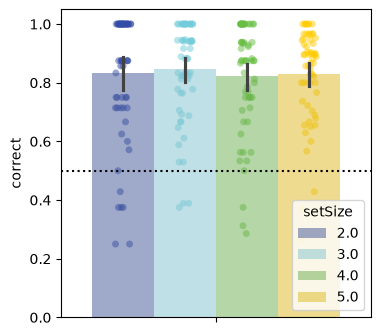

In [15]:
# Let's look at the performance as a function of set size
# We'll just use a bar plot and we will overlap points over it
collins_palette={
  2.0: (0.2,0.30,0.65),
  3.0: (0.45,0.80,0.86),
  4.0: (0.4,0.75,0.25),
  5.0: (1.0,0.8,0.0)
}
fig,ax = plt.subplots(figsize=(4,4))
sns.stripplot(data=df_rlwm_test_avg, y='correct', hue='setSize', palette=collins_palette, ax=ax, alpha=0.5, dodge=True, legend=False, zorder=1)
sns.barplot(data=df_rlwm_test_avg, y='correct', hue='setSize', palette=collins_palette, ax=ax, alpha=0.5, zorder=1)
ax.axhline(y=0.5, linestyle=':', color='k')

# What can you tell "by eye" when looking at this plot?
# Why do you think you are seeing this result?

In [16]:
# Let's run a statistical analysis to confirm our visual impression
model = smf.mixedlm(
    "correct ~ setSize",
    data=df_rlwm_test_avg,
    groups=df_rlwm_test_avg["subjid"]
)

res = model.fit()
print(res.summary())

        Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: correct 
No. Observations: 244     Method:             REML    
No. Groups:       61      Scale:              0.0155  
Min. group size:  4       Log-Likelihood:     103.9000
Max. group size:  4       Converged:          Yes     
Mean group size:  4.0                                 
------------------------------------------------------
            Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------
Intercept    0.845    0.031 27.088 0.000  0.784  0.906
setSize     -0.003    0.007 -0.475 0.635 -0.017  0.011
Group Var    0.018    0.036                           



In [17]:
df_rlwm_test_avg

,subjid,setSize,trial_index,time_elapsed,rt,timeEndTrial,blockId,setId,stimId,correct_feedback,key_response,correct,time_startFadeIn,time_endFadeIn,feedback,imageid,setid,STAI,PSS,BDI
0,558a327cfdf99b2d75651681,2.0,918.777778,1.621926e+06,871.300000,1.628173e+06,5.666667,5.666667,3.444444,1.222222,2.555556,1.000000,1.626694e+06,1.626803e+06,1.222222,NaN,NaN,32.0,20.0,24.0
1,558a327cfdf99b2d75651681,3.0,916.888889,1.620345e+06,828.600000,1.626592e+06,6.000000,6.000000,2.000000,1.444444,1.888889,1.000000,1.625161e+06,1.625269e+06,1.444444,NaN,NaN,32.0,20.0,24.0
2,558a327cfdf99b2d75651681,4.0,926.500000,1.630198e+06,771.212500,1.636445e+06,1.000000,1.000000,3.250000,1.500000,2.500000,0.750000,1.635071e+06,1.635178e+06,1.250000,NaN,NaN,32.0,20.0,24.0
3,558a327cfdf99b2d75651681,5.0,917.689655,1.621279e+06,796.765517,1.627526e+06,6.068966,6.068966,2.620690,1.413793,1.965517,0.896552,1.626127e+06,1.626235e+06,1.241379,NaN,NaN,32.0,20.0,24.0
4,571a1295c97ad400123ab3bd,2.0,959.400000,1.558739e+06,686.220000,1.559354e+06,3.800000,3.800000,2.600000,1.200000,2.400000,1.000000,1.558066e+06,1.558176e+06,1.200000,NaN,NaN,67.0,35.0,62.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
239,648bc27efabf8d80521cafc1,5.0,919.066667,1.837040e+06,1132.866667,1.845311e+06,5.333333,5.333333,2.533333,1.400000,2.400000,0.666667,1.843553e+06,1.843663e+06,1.000000,NaN,NaN,59.0,37.0,60.0
240,64ad91fb5b61d9574d94e15c,2.0,923.571429,1.581463e+06,1053.557143,1.583564e+06,3.142857,3.142857,3.714286,1.285714,2.285714,0.714286,1.581908e+06,1.582015e+06,1.000000,NaN,NaN,48.0,28.0,30.0
241,64ad91fb5b61d9574d94e15c,3.0,917.352941,1.574860e+06,996.176471,1.576961e+06,6.882353,6.882353,2.000000,1.470588,2.000000,0.941176,1.575363e+06,1.575472e+06,1.411765,NaN,NaN,48.0,28.0,30.0
242,64ad91fb5b61d9574d94e15c,4.0,918.500000,1.575960e+06,1060.200000,1.578061e+06,9.000000,9.000000,3.250000,1.500000,1.625000,0.375000,1.576399e+06,1.576507e+06,0.625000,NaN,NaN,48.0,28.0,30.0


In [18]:
# Let's digger deeper to see whether overall performance in the learning and test phases are correlated
# To do this, we'll start by merging information from df_rlwm_avg and df_rlwm_test_avg
# However, they have the same column names, so the merge operation would be confusing if we don't do anything about it. Let's first rename the 'correct' columns
df_rlwm_avg.rename(columns={'correct': 'correct_learning'}, inplace=True)
df_rlwm_test_avg.rename(columns={'correct': 'correct_test'}, inplace=True)
# Now, we are ready to merge. We will simply bring the correct_test column of df_rlwm_test_avg into df_rlwm_avg
df_rlwm_avg=df_rlwm_avg.merge(df_rlwm_test_avg[['subjid', 'correct_test']], on="subjid", how="left")
# Actually, df_rlwm_avg still separate data as a function of stim_rep(etition), let's get rid of that
df_rlwm_avg=df_rlwm_avg.groupby(by=['subjid', 'setSize']).mean(numeric_only=True).reset_index()
# Let's look at our new df_rlwm_avg. The correct_test column should appear as the last column
display(df_rlwm_avg)

,subjid,setSize,stim_rep,trial_index,time_elapsed,rt,timeEndTrial,blockId,setId,stimId,...,correct_learning,time_startFadeIn,time_endFadeIn,feedback,imageid,setid,STAI,PSS,BDI,correct_test
0,558a327cfdf99b2d75651681,2.0,4.5,383.200000,583445.150000,626.540000,589692.090000,4.000000,9.000000,2.750000,...,0.900000,588062.785000,588170.255000,1.600000,2.750000,9.000000,32.0,20.0,24.0,0.911638
1,558a327cfdf99b2d75651681,3.0,4.5,394.333333,583423.833333,698.073333,589671.001111,4.333333,6.000000,2.000000,...,0.866667,587969.898889,588078.964444,1.288889,2.000000,6.000000,32.0,20.0,24.0,0.911638
2,558a327cfdf99b2d75651681,4.0,4.5,548.425000,775508.135714,786.540000,781755.165714,5.957143,0.492857,2.746429,...,0.750000,779966.131250,780074.433571,1.141071,2.746429,0.492857,32.0,20.0,24.0,0.911638
3,558a327cfdf99b2d75651681,5.0,4.5,480.489231,695672.491795,719.376205,701919.635128,5.353846,6.000000,2.510769,...,0.837949,700197.677077,700305.869795,1.276410,2.510769,6.000000,32.0,20.0,24.0,0.911638
4,571a1295c97ad400123ab3bd,2.0,4.5,385.000000,546909.500000,661.005000,547524.675000,4.000000,1.000000,2.500000,...,0.850000,545861.715000,545971.795000,1.400000,2.500000,1.000000,67.0,35.0,62.0,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
271,648bc27efabf8d80521cafc1,5.0,4.5,498.355513,876455.823077,943.377436,884726.778269,5.551282,5.616667,2.545897,...,0.745641,882759.326474,882869.648205,1.069103,2.545897,5.616667,59.0,37.0,60.0,0.771359
272,64ad91fb5b61d9574d94e15c,2.0,4.5,383.000000,543192.600000,680.240000,545292.905000,4.000000,2.000000,2.500000,...,0.850000,543610.970000,543719.365000,1.400000,2.500000,2.000000,48.0,28.0,30.0,0.714512
273,64ad91fb5b61d9574d94e15c,3.0,4.5,395.358730,557571.217460,841.546349,559671.619365,4.342857,6.714286,1.957143,...,0.833333,557828.082381,557936.269524,1.246032,1.957143,6.714286,48.0,28.0,30.0,0.714512
274,64ad91fb5b61d9574d94e15c,4.0,4.5,553.000000,752875.637500,880.528750,754976.033750,6.000000,4.500000,2.725000,...,0.712500,753093.330000,753200.845000,1.000000,2.725000,4.500000,48.0,28.0,30.0,0.714512


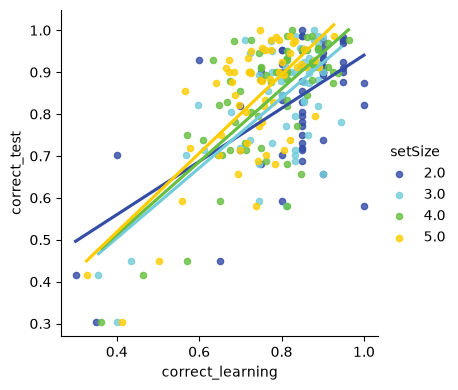

In [19]:
# Ok, now, let's plot the correlation between the two types of accuracies
collins_palette={
  2.0: (0.2,0.30,0.65),
  3.0: (0.45,0.80,0.86),
  4.0: (0.4,0.75,0.25),
  5.0: (1.0,0.8,0.0)
}
g=sns.lmplot(data=df_rlwm_avg, x='correct_learning', y='correct_test', hue='setSize', palette=collins_palette, height=4, aspect=1,scatter_kws={"s": 20}, ci=None)

# What can you see?

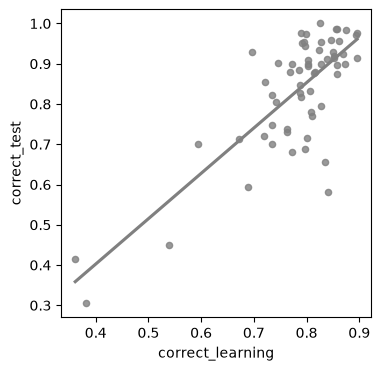

In [20]:
# To compute the correlation, let's reduce even further our dataframe to exclude setSize
df_rlwm_avg_nosetsize=df_rlwm_avg.groupby(by=['subjid']).mean(numeric_only=True).reset_index()
# Let plot the overall correlation first
fig, ax= plt.subplots(figsize=(4,4))
g=sns.regplot(data=df_rlwm_avg_nosetsize, x='correct_learning', y='correct_test', color="gray", scatter_kws={"s": 20}, ci=None)

# What can you see? Do you think you can run a standard Pearson correlation test on this data?

In [21]:
# Let's check if our data is normally distributed
# import the statistical test for normality
from scipy.stats import shapiro

cols = ["correct_learning", "correct_test"]
for col in cols:
    x = df_rlwm_avg_nosetsize[col].dropna()
    stat, p = shapiro(x)
    print(f"{col}: W={stat:.4f}, p={p:.4g}")

# What can you see?

correct_learning: W=0.7754, p=6.672e-09
correct_test: W=0.8502, p=2.637e-06


In [22]:
# Perhaps we should not use a test whose validity depends on a normality assumption...
# We will compare both types of correlation tests using the .corr() methods provided by Pandas
print("Pearson r:", df_rlwm_avg_nosetsize[["correct_learning", "correct_test"]].corr(method="pearson").iloc[0,1])
print("Spearman r:", df_rlwm_avg_nosetsize[["correct_learning", "correct_test"]].corr(method="spearman").iloc[0,1])

# What do you see?

Pearson r: 0.7803133238597805
Spearman r: 0.6001401393985528


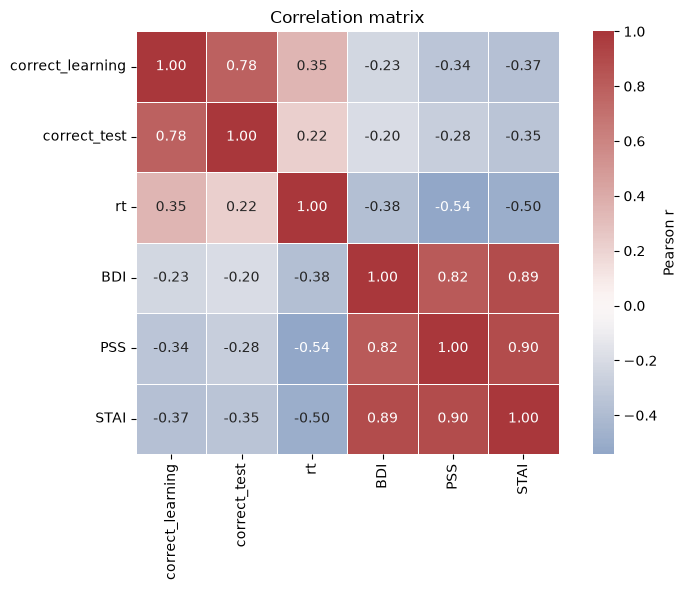

In [ ]:
# To finish, we'll look at the broader correlation structure of our data.
# We don't have any specific hypothesis in mind, we are just curious and we want to look at the relation between our variables all at once 
# This has implications when it comes to reporting such findings in the literature.. Which ones?
# Let's only keep the columns we want for this analysis
df_rlwm_correlation_matrix=df_rlwm_avg_nosetsize[['correct_learning', 'correct_test', 'rt', 'BDI', 'PSS', 'STAI']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    df_rlwm_correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson r"}
)

plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

# What can you see?